In [1]:
import os
import sys

REPO = "Arabic-sarcasm"

if not os.path.exists(f"/content/{REPO}"):
    !git clone https://github.com/cad0m/{REPO}.git /content/{REPO}
else:
    !git -C /content/{REPO} pull

%cd /content/{REPO}

if f"/content/{REPO}" not in sys.path:
    sys.path.insert(0, f"/content/{REPO}")

!pip install -q uv
!uv pip install --system emoji tashaphyne

Cloning into '/content/Arabic-sarcasm'...
remote: Enumerating objects: 245, done.
remote: Counting objects: 100% (245/245), done.
remote: Compressing objects: 100% (163/163), done.
remote: Total 245 (delta 118), reused 169 (delta 61), pack-reused 0 (from 0)
Receiving objects: 100% (245/245), 1.77 MiB | 2.45 MiB/s, done.
Resolving deltas: 100% (118/118), done.
/content/Arabic-sarcasm
Using Python 3.13.16 environment at: /usr
Resolved 4 packages in 567ms
Prepared 3 packages in 72ms
Installed 3 packages in 12ms
 + emoji==2.16.0
 + pyarabic==0.6.15
 + tashaphyne==0.3.6


# TP2 — Part B: PLM used directly (no training)

**What this notebook covers (run it once, top to bottom):**

| TP item | Where |
|---|---|
| B1 zero-shot NLI (mDeBERTa), ≥ 3 hypothesis wordings (ar / fr / en), score thresholded **on val** | §2 |
| B1 sensitivity to wording, score definition, input preprocessing | §2.2 – §2.5 |
| Q4: why NLI can classify without examples, role of premise/hypothesis attention (+ attention demo) | §2.7 |
| B2 sentiment transfer (CamelBERT-DA) + rule "negative ⇒ sarcastic", `id2label` inspection | §3 |
| Q5: precision / recall / F1, sarcasm ↔ sentiment relation, contamination | §3.3 – §3.6 |
| Part G inputs for B models: CPU latency, model size | §2.8, §3.7 |
| Logging (`results/results.csv`) + predictions (`predictions/*.csv`) | automatic |

**Protocol respected:** every choice (template, score definition, preprocessing, threshold) is made on `val`.
The official test set is only touched in the *final* cell of §2.6 and §3.6, once, for the retained B1 and B2 models
(so you never have to re-run). Nothing is selected on test.

Requirements: `pip install transformers torch scikit-learn emoji seaborn` (+ your existing `src/` helpers).

In [2]:
import os, sys, time, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT))          # results/ and predictions/ live at the repo root
warnings.filterwarnings("ignore")

import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt, seaborn as sns
from scipy.stats import spearmanr
from sklearn.metrics import (accuracy_score, average_precision_score, confusion_matrix, f1_score,
                             roc_auc_score)
from transformers import AutoModelForSequenceClassification, AutoTokenizer, pipeline

from src.data import get_data
from src.evaluate import latency_per_tweet, log_result, metrics, save_predictions
from src.preprocess import build_pipeline
from src.train import best_threshold, set_seed
from src import analysis as A
from src.plm import cached_npz, choose_max_length, get_device, length_stats, plot_lengths, truncation_table

SEED = 42
set_seed(SEED)
DEVICE = get_device()
CACHE, FIG = ROOT / "results" / "cache", ROOT / "results" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid")
print("device:", DEVICE)

device: cuda


In [3]:
train, val, test, report = get_data()
y_val, y_test = val["sarcasm"].values, test["sarcasm"].values
print(f"train={len(train)}  val={len(val)}  test={len(test)}")
print(f"sarcasm rate  val={y_val.mean():.3f}  test={y_test.mean():.3f}")

# reference points for reading the scores below
p = y_val.mean()
print(f"\nReferences on val: always-sarcastic F1 = {2*p/(1+p):.3f} | random PR-AUC = {p:.3f} (= base rate)")

# Preprocessing variants for PLMs: keep the cues (emoji, elongation, punctuation, laughter), only remove noise.
PREPS = {
    "raw": lambda t: t,
    "base": build_pipeline(["html", "mentions", "hashtags"]),                      # same as TF-IDF base
    "clean": lambda t: build_pipeline(["html", "hashtags"])(A.remove_urls_mentions(t)),  # no URL / @user at all
    "clean+emoji": lambda t: build_pipeline(["html", "hashtags", "emoji"])(A.remove_urls_mentions(t)),
}
PREP_NLI = "clean"   # default for the template sweep; ablated in §2.5
for n, f in PREPS.items():
    print(f"{n:<12}", f(val['tweet'].iloc[1])[:90])

train=10842  val=1255  test=3000
sarcasm rate  val=0.173  test=0.274

References on val: always-sarcastic F1 = 0.295 | random PR-AUC = 0.173 (= base rate)
raw          "ولو قصفت طائراتهم وأضافوا عشرين دولة معهم. لن يغيروا مجرى التاريخ ولن يفلتوا من الانتقام 
base         "ولو قصفت طائراتهم وأضافوا عشرين دولة معهم. لن يغيروا مجرى التاريخ ولن يفلتوا من الانتقام 
clean        "ولو قصفت طائراتهم وأضافوا عشرين دولة معهم. لن يغيروا مجرى التاريخ ولن يفلتوا من الانتقام 
clean+emoji  "ولو قصفت طائراتهم وأضافوا عشرين دولة معهم. لن يغيروا مجرى التاريخ ولن يفلتوا من الانتقام 


## 1. Helper: scoring, thresholding on val
Every score is turned into a decision with the **threshold that maximises sarcastic-class F1 on val**
(`best_threshold`). PR-AUC / ROC-AUC are threshold-free and show the ranking quality of the raw score.

In [4]:
def evaluate_scores(y, s):
    thr = best_threshold(y, s)
    m = metrics(y, s, thr)
    m["roc_auc"] = roc_auc_score(y, s)
    return thr, m

def softmax(a):
    e = np.exp(a - a.max(-1, keepdims=True))
    return e / e.sum(-1, keepdims=True)

def total_params(model):
    return sum(p.numel() for p in model.parameters())

## 2. B1 — Zero-shot NLI (`mDeBERTa-v3-base-xnli-multilingual-nli-2mil7`)

Principle: premise = tweet, hypothesis = "This tweet is sarcastic." The NLI head outputs
`entailment / neutral / contradiction`; the entailment probability is the evidence that the tweet is sarcastic.
We compute the NLI logits **ourselves** (same thing as the `zero-shot-classification` pipeline, but one forward
pass gives us several possible score definitions and we can cache them).

In [5]:
NLI = "MoritzLaurer/mDeBERTa-v3-base-xnli-multilingual-nli-2mil7"
nli_tok = AutoTokenizer.from_pretrained(NLI)
nli = AutoModelForSequenceClassification.from_pretrained(NLI).to(DEVICE).eval()
print("id2label:", nli.config.id2label)
l2i = {k.lower(): v for k, v in nli.config.label2id.items()}
ENT, CON = l2i["entailment"], l2i["contradiction"]

NLI_MAX = 256   # default, replaced by the data-driven value computed in the next cell

# Required: ar / fr / en. Two extra wordings ("the author is being ...") to see how fragile the model is.
TEMPLATES = {
    "ar":         dict(template="هذه التغريدة {}.", sarc="ساخرة", serious="جادة"),
    "fr":         dict(template="Ce tweet est {}.", sarc="sarcastique", serious="sérieux"),
    "en":         dict(template="This tweet is {}.", sarc="sarcastic", serious="serious"),
    "ar_author":  dict(template="كاتب هذه التغريدة يتكلم بشكل {}.", sarc="ساخر", serious="جدي"),
    "en_author":  dict(template="The author of this tweet is being {}.", sarc="sarcastic", serious="sincere"),
}

@torch.no_grad()
def nli_logits(premises, hypotheses, model=None, device=None, bs=64, max_length=None):
    model, device, max_length = model or nli, device or DEVICE, max_length or NLI_MAX
    order = np.argsort([len(p) for p in premises])
    out = np.zeros((len(premises), model.config.num_labels), dtype=np.float32)
    for i in range(0, len(order), bs):
        idx = order[i:i + bs]
        batch = nli_tok([premises[j] for j in idx], [hypotheses[j] for j in idx], padding=True,
                        truncation="only_first", max_length=max_length, return_tensors="pt").to(device)
        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=device.type == "cuda"):
            logits = model(**batch).logits
        out[idx] = logits.float().cpu().numpy()
    return out

def get_logits(tpl, prep, split, df):
    """NLI logits for 'sarcastic' and 'serious' hypotheses (cached on disk)."""
    spec = TEMPLATES[tpl]
    texts = [PREPS[prep](t) for t in df["tweet"]]
    def run():
        start = time.time()
        ls = nli_logits(texts, [spec["template"].format(spec["sarc"])] * len(texts))
        ln = nli_logits(texts, [spec["template"].format(spec["serious"])] * len(texts))
        return {"ls": ls, "ln": ln, "seconds": np.array(time.time() - start)}
    return cached_npz(CACHE / f"b1_{prep}_{tpl}_{split}_{len(df)}.npz", run)

def score_variants(d):
    """Different ways of turning NLI logits into P(sarcastic)."""
    ls, ln = d["ls"], d["ln"]
    p_s, p_n = softmax(ls), softmax(ln)
    return {
        "softmax2":    softmax(np.stack([ls[:, ENT], ln[:, ENT]], 1))[:, 0],      # = HF zero-shot pipeline default
        "entail":      p_s[:, ENT],                                               # only the sarcastic hypothesis
        "ent_vs_con":  softmax(ls[:, [ENT, CON]])[:, 0],                          # = pipeline with multi_label=True
        "contrast":    (p_s[:, ENT] - p_n[:, ENT] + 1) / 2,                       # sarcastic minus serious entailment
    }

config.json:   0%|          | 0.00/1.09k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/467 [00:00<?, ?B/s]

spm.model: reconstructing file:   0%|          |  0.00B / 4.31MB            

spm.model: downloading bytes:           |  0.00B            

tokenizer.json: reconstructing file:   0%|          |  0.00B / 16.3MB            

...

special_tokens_map.json:   0%|          | 0.00/173 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  558MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

id2label: {0: 'entailment', 1: 'neutral', 2: 'contradiction'}


### 1.1 Max sequence length for the NLI model (decided on train; premise + hypothesis counted together)
Rule: `LENGTH_RULE` on the token length of *tweet + longest hypothesis*, rounded up to a multiple of 8. Truncation is `only_first`,
so only the tweet is ever cut, never the hypothesis. (Mean ± k·std is avoided: lengths are right-skewed.)

longest hypothesis: كاتب هذه التغريدة يتكلم بشكل ساخر. | 17 tokens


,mean,std,median,q1,q3,tukey_fence,max_non_outlier,p95,p99,p99.5,mean+3std,max
NLI pair | clean,52.7,16.1,52.0,41.0,63.0,96.0,96,74.0,112.0,125.0,101.0,185


rule = p99.5 -> NLI_MAX = 128


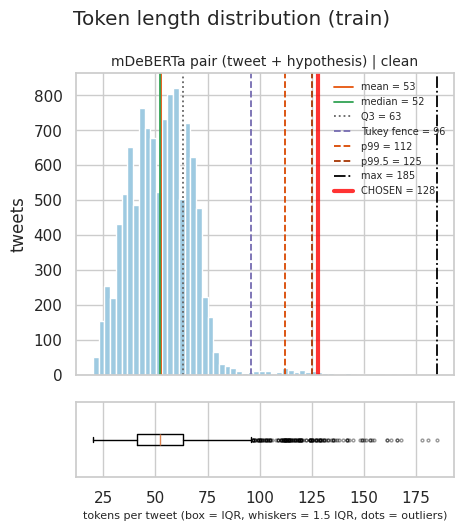

,train (%),val (%),test (%)
cap,,,
tukey = 96,1.47,0.80,8.23
p99 = 112,0.96,0.32,5.43
p99.5 = 128,0.41,0.24,2.23
mean+3std = 104,1.20,0.64,6.47
max = 192,0.00,0.00,0.03
CHOSEN = 128,0.41,0.24,2.23


In [6]:
LENGTH_RULE = "p99.5"      # "tukey" | "p99" | "p99.5" | "mean+3std" | "max"
hyps = [t["template"].format(w) for t in TEMPLATES.values() for w in (t["sarc"], t["serious"])]
longest_hyp = max(hyps, key=lambda h: len(nli_tok(h)["input_ids"]))
print("longest hypothesis:", longest_hyp, "|", len(nli_tok(longest_hyp)["input_ids"]), "tokens")

def pair_lengths(df, prep):
    texts = [PREPS[prep](t) for t in df["tweet"]]
    ids = nli_tok(texts, [longest_hyp] * len(texts), truncation=True, max_length=512)["input_ids"]
    return np.array([len(x) for x in ids])

NLI_LEN = {s: pair_lengths(df, PREP_NLI) for s, df in [("train", train), ("val", val), ("test", test)]}
st = length_stats(NLI_LEN["train"])
display(pd.DataFrame([st], index=[f"NLI pair | {PREP_NLI}"]).round(1))
NLI_MAX = choose_max_length(st, LENGTH_RULE)
print(f"rule = {LENGTH_RULE} -> NLI_MAX = {NLI_MAX}")
plot_lengths({f"mDeBERTa pair (tweet + hypothesis) | {PREP_NLI}": NLI_LEN["train"]}, chosen={f"mDeBERTa pair (tweet + hypothesis) | {PREP_NLI}": NLI_MAX},
             path=FIG / "b1_token_length_distribution.png")
cand = {r: choose_max_length(st, r) for r in ["tukey", "p99", "p99.5", "mean+3std", "max"]}; cand["CHOSEN"] = NLI_MAX
display((truncation_table(NLI_LEN, cand) * 100).round(2).rename_axis("cap").rename(columns=lambda c: c + " (%)"))

### 2.1 Template × score-definition sweep on val (this is the slow cell: 5 templates × 2 hypotheses; cached afterwards)

In [7]:
rows, VAL_SCORES, VAL_SECONDS = [], {}, {}
for tpl in TEMPLATES:
    d = get_logits(tpl, PREP_NLI, "val", val)
    VAL_SECONDS[tpl] = float(d["seconds"])
    for sc, s in score_variants(d).items():
        VAL_SCORES[(tpl, sc)] = s
        thr, m = evaluate_scores(y_val, s)
        rows.append({"template": tpl, "score": sc, "threshold": thr, **m})

# ensemble of the three required languages (mean of the default score) — shows whether wording noise averages out
VAL_SCORES[("ensemble3", "softmax2")] = np.mean([VAL_SCORES[(t, "softmax2")] for t in ("ar", "fr", "en")], 0)
thr, m = evaluate_scores(y_val, VAL_SCORES[("ensemble3", "softmax2")])
rows.append({"template": "ensemble3", "score": "softmax2", "threshold": thr, **m})

sweep = pd.DataFrame(rows)
display(sweep.pivot(index="template", columns="score", values="f1").round(4).rename_axis(columns="val F1 (sarcastic)"))
display(sweep.pivot(index="template", columns="score", values="pr_auc").round(4).rename_axis(columns="val PR-AUC"))

val F1 (sarcastic),contrast,ent_vs_con,entail,softmax2
template,,,,
ar,0.4111,0.3835,0.3792,0.4105
ar_author,0.3843,0.3374,0.3628,0.3892
en,0.4090,0.3788,0.3796,0.4088
en_author,0.4164,0.4007,0.3935,0.4637
ensemble3,NaN,NaN,NaN,0.4056
fr,0.4132,0.3710,0.3703,0.4074


val PR-AUC,contrast,ent_vs_con,entail,softmax2
template,,,,
ar,0.3491,0.3005,0.3303,0.3448
ar_author,0.3274,0.2777,0.3149,0.3220
en,0.3404,0.2854,0.3102,0.3299
en_author,0.3768,0.3361,0.3433,0.3995
ensemble3,NaN,NaN,NaN,0.3449
fr,0.3413,0.2934,0.3280,0.3323


### 2.2 Sensitivity to the wording (Q4)

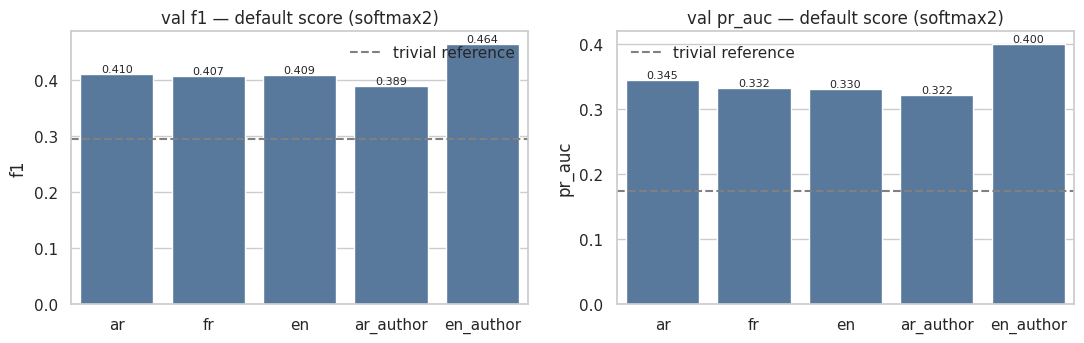

Spearman correlation between the scores produced by the different wordings (1 = same ranking of tweets):


,ar,fr,en,ar_author,en_author
ar,1.00,0.82,0.80,0.78,0.74
fr,0.82,1.00,0.95,0.80,0.77
en,0.80,0.95,1.00,0.80,0.73
ar_author,0.78,0.80,0.80,1.00,0.70
en_author,0.74,0.77,0.73,0.70,1.00


F1 range over wordings: 0.389 – 0.464  (Δ = 0.074)


In [8]:
req = sweep[(sweep.score == "softmax2") & sweep.template.isin(["ar", "fr", "en", "ar_author", "en_author"])]
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
for a, col in zip(ax, ["f1", "pr_auc"]):
    sns.barplot(data=req, x="template", y=col, ax=a, color="#4C78A8")
    a.axhline(2*p/(1+p) if col == "f1" else p, color="grey", ls="--", label="trivial reference")
    a.set_title(f"val {col} — default score (softmax2)"); a.set_xlabel(""); a.legend(frameon=False)
    for c in a.containers: a.bar_label(c, fmt="%.3f", fontsize=8)
plt.tight_layout(); plt.savefig(FIG / "b1_template_sensitivity.png", dpi=200); plt.show()

names = ["ar", "fr", "en", "ar_author", "en_author"]
corr = pd.DataFrame([[spearmanr(VAL_SCORES[(a, "softmax2")], VAL_SCORES[(b, "softmax2")])[0] for b in names] for a in names],
                    index=names, columns=names)
print("Spearman correlation between the scores produced by the different wordings (1 = same ranking of tweets):")
display(corr.round(2))
spread = req.set_index("template")[["f1", "pr_auc"]]
print(f"F1 range over wordings: {spread.f1.min():.3f} – {spread.f1.max():.3f}  (Δ = {spread.f1.max()-spread.f1.min():.3f})")

### 2.3 Select the best configuration on val and log every wording

In [9]:
# best score definition per template (selected on val F1) -> one logged row per wording
best_per_tpl = sweep.sort_values("f1", ascending=False).groupby("template").head(1).set_index("template")
display(best_per_tpl[["score", "threshold", "f1", "pr_auc", "macro_f1", "precision", "recall", "roc_auc"]].round(4))

N_PARAMS_NLI = total_params(nli)
for tpl, r in best_per_tpl.iterrows():
    log_result(model=f"b1_zeroshot_{tpl}", preprocessing=PREP_NLI, seed=0, threshold=r.threshold,
               train_time=0.0, trained_params=0, total_params=N_PARAMS_NLI, score_def=r.score,
               inference_time_val=VAL_SECONDS.get(tpl, np.nan),
               **{f"val_{k}": r[k] for k in ["f1", "pr_auc", "macro_f1", "precision", "recall", "roc_auc"]})

BEST_TPL = best_per_tpl["f1"].idxmax()
print("Best on val:", BEST_TPL, "| score:", best_per_tpl.loc[BEST_TPL, "score"], "| F1 =", round(best_per_tpl.loc[BEST_TPL, "f1"], 4))

,score,threshold,f1,pr_auc,macro_f1,precision,recall,roc_auc
template,,,,,,,,
en_author,softmax2,0.8754,0.4637,0.3995,0.6636,0.4041,0.5438,0.7529
fr,contrast,0.5037,0.4132,0.3413,0.6002,0.3060,0.6359,0.6916
ar,contrast,0.5015,0.4111,0.3491,0.5595,0.2780,0.7880,0.7144
en,contrast,0.5276,0.4090,0.3404,0.5980,0.3036,0.6267,0.6972
ensemble3,softmax2,0.7323,0.4056,0.3449,0.5678,0.2804,0.7327,0.7204
ar_author,softmax2,0.7894,0.3892,0.3220,0.5669,0.2753,0.6636,0.7019


Best on val: en_author | score: softmax2 | F1 = 0.4637


### 2.4 Which score definition is best? (Q4: the pipeline default is `softmax2`)

In [10]:
display(sweep.groupby("score")[["f1", "pr_auc", "roc_auc"]].mean().round(4))

,f1,pr_auc,roc_auc
score,,,
contrast,0.4068,0.3470,0.7025
ent_vs_con,0.3743,0.2986,0.6575
entail,0.3771,0.3253,0.6767
softmax2,0.4142,0.3456,0.7187


### 2.5 Does preprocessing matter for the PLM? (ablation on the best wording — feeds Q3)

In [11]:
ABL_TPL = "en" if BEST_TPL == "ensemble3" else BEST_TPL            # ensemble: ablate on a single wording
ABL_SCORE = "softmax2" if BEST_TPL == "ensemble3" else best_per_tpl.loc[BEST_TPL, "score"]
rows = []
for prep in PREPS:
    d = get_logits(ABL_TPL, prep, "val", val)
    thr, m = evaluate_scores(y_val, score_variants(d)[ABL_SCORE])
    rows.append({"preprocessing": prep, "threshold": thr, **m})
prep_ablation = pd.DataFrame(rows).set_index("preprocessing")
display(prep_ablation[["f1", "pr_auc", "macro_f1", "precision", "recall", "roc_auc"]].round(4))
BEST_PREP = prep_ablation["f1"].idxmax()
print("Preprocessing retained for the NLI model:", BEST_PREP)

,f1,pr_auc,macro_f1,precision,recall,roc_auc
preprocessing,,,,,,
raw,0.4741,0.4379,0.6650,0.3963,0.5899,0.7617
base,0.4726,0.4122,0.6659,0.4006,0.5760,0.7555
clean,0.4637,0.3995,0.6636,0.4041,0.5438,0.7529
clean+emoji,0.4479,0.3873,0.6307,0.3405,0.6544,0.7501


Preprocessing retained for the NLI model: raw


### 2.6 Final B1 model: test scores, predictions, latency (the only place test is used for B1)

In [12]:
# candidates: each wording with its best score + the 3-language ensemble; retained = best val F1
def scores_for(name, df, split, prep):
    if name == "ensemble3":
        return np.mean([score_variants(get_logits(t, prep, split, df))["softmax2"] for t in ("ar", "fr", "en")], 0)
    return score_variants(get_logits(name, prep, split, df))[best_per_tpl.loc[name, "score"]]

cand = {n: evaluate_scores(y_val, scores_for(n, val, "val", BEST_PREP)) for n in list(TEMPLATES) + ["ensemble3"]}
B1_NAME = max(cand, key=lambda n: cand[n][1]["f1"])
B1_THR, B1_VAL = cand[B1_NAME]
print("B1 retained:", B1_NAME, "| prep:", BEST_PREP, "| val F1 =", round(B1_VAL["f1"], 4), "| threshold =", round(B1_THR, 4))

s_test = scores_for(B1_NAME, test, "test", BEST_PREP)   # test is scored for the retained model only
B1_TEST = metrics(y_test, s_test, B1_THR)
B1_TEST["roc_auc"] = roc_auc_score(y_test, s_test)
print("B1 final test:", {k: round(v, 4) for k, v in B1_TEST.items()})

# CPU latency (batch of 1, all hypotheses of the retained configuration)
tpls = ["ar", "fr", "en"] if B1_NAME == "ensemble3" else [B1_NAME]
nli_cpu = AutoModelForSequenceClassification.from_pretrained(NLI).float().cpu().eval()
cpu = torch.device("cpu")
def predict_b1_cpu(texts):
    for t in texts:
        x = PREPS[BEST_PREP](t)
        for tpl in tpls:
            sp = TEMPLATES[tpl]
            for w in (sp["sarc"], sp["serious"]):
                nli_logits([x], [sp["template"].format(w)], model=nli_cpu, device=cpu, bs=1)
B1_LAT = latency_per_tweet(predict_b1_cpu, val["tweet"].tolist()[:30])
print(f"CPU latency ≈ {B1_LAT*1000:.0f} ms / tweet ({2*len(tpls)} NLI passes per tweet)")

save_predictions(f"b1_zeroshot_{B1_NAME}", 0, test["id"].values, y_test, s_test, B1_THR)
log_result(model=f"b1_zeroshot_{B1_NAME}", preprocessing=BEST_PREP, seed=0, threshold=B1_THR, train_time=0.0,
           trained_params=0, total_params=N_PARAMS_NLI, latency_cpu_s=B1_LAT,
           **{f"val_{k}": v for k, v in B1_VAL.items()}, **{f"test_{k}": v for k, v in B1_TEST.items()})

B1 retained: en_author | prep: raw | val F1 = 0.4741 | threshold = 0.8739
B1 final test: {'f1': 0.4876, 'pr_auc': np.float64(0.4308), 'macro_f1': 0.6255, 'precision': 0.4302, 'recall': 0.5627, 'roc_auc': np.float64(0.688)}


Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

CPU latency ≈ 746 ms / tweet (2 NLI passes per tweet)


### 2.7 Q4 — how can an NLI model classify without any training example? What does attention do?
Below: a look at the cross-attention between *premise* (tweet) and *hypothesis* in the retained wording.

In [13]:
@torch.no_grad()
def hyp_to_premise_attention(tweet, hypothesis):
    batch = nli_tok(tweet, hypothesis, return_tensors="pt", truncation="only_first", max_length=NLI_MAX).to(DEVICE)
    out = nli(**batch, output_attentions=True)
    ids = batch["input_ids"][0].tolist()
    seps = [i for i, t in enumerate(ids) if t == nli_tok.sep_token_id]
    prem, hyp = slice(1, seps[0]), slice(seps[0] + 1, seps[1])
    share, last = [], None
    for att in out.attentions:                     # (1, heads, L, L)
        a = att[0].float().mean(0)                 # average over heads
        share.append(a[hyp][:, prem].sum(1).mean().item())
        last = a
    received = last[hyp][:, prem].mean(0).cpu().numpy()
    toks = nli_tok.convert_ids_to_tokens(ids[prem])
    return np.array(share), toks, received

try:
    ex = val[val.sarcasm == 1].iloc[3]["tweet"]
    sp = TEMPLATES[tpls[0]]
    share, toks, received = hyp_to_premise_attention(PREPS[BEST_PREP](ex), sp["template"].format(sp["sarc"]))
    print("share of the hypothesis tokens' attention that goes to the premise, per layer:")
    print(np.round(share, 2))
    top = np.argsort(-received)[:8]
    print("premise tokens most attended by the hypothesis in the last layer:", [(toks[i], round(float(received[i]), 3)) for i in top])
except Exception as e:      # some transformers versions do not return DeBERTa attentions
    print("attention demo skipped:", repr(e))

share of the hypothesis tokens' attention that goes to the premise, per layer:
[0.35 0.34 0.19 0.21 0.32 0.12 0.16 0.11 0.18 0.18 0.12 0.18]
premise tokens most attended by the hypothesis in the last layer: [('▁', 0.039), ('▁"#', 0.021), ('ومب', 0.013), ('▁', 0.013), ('_', 0.008), ('حل', 0.008), ('الن', 0.007), ('صار', 0.007)]


**Éléments de réponse (Q4, à adapter avec vos chiffres) :**

* *Pourquoi sans exemple ?* Le modèle a été fine-tuné sur de l'**inférence en langage naturel** multilingue (XNLI + MNLI + ANLI…, 2,7 M de paires) : il sait dire si une *prémisse* **implique** une *hypothèse*. La classification devient alors une question de compréhension : « le tweet implique-t-il que *ce tweet est sarcastique* ? ». Les étiquettes sont verbalisées dans l'hypothèse, donc n'importe quelle classe exprimable en langage naturel peut être testée, sans tête de classification dédiée. Le transfert multilingue (mDeBERTa) permet de formuler l'hypothèse en arabe, français ou anglais.
* *Rôle de l'attention prémisse ↔ hypothèse.* Prémisse et hypothèse sont **concaténées dans une même séquence** `[CLS] prémisse [SEP] hypothèse [SEP]` et traitées par l'auto-attention bidirectionnelle d'un **cross-encoder** : chaque jeton de l'hypothèse (« sarcastique ») peut regarder les jetons du tweet et réciproquement, couche après couche (voir la part d'attention hypothèse→prémisse par couche ci-dessus). C'est cette interaction qui permet de comparer le contenu du tweet à la propriété demandée ; un bi-encodeur (deux vecteurs comparés par cosinus) n'aurait pas cette finesse. Le coût : une passe par couple (tweet, hypothèse) → 2 passes par tweet ici.
* *Sensibilité à la formulation :* voir §2.2 (Δ F1 entre formulations et corrélation de Spearman entre les scores). La nécessité de **seuiller sur val** vient du fait que la probabilité d'implication n'est pas calibrée pour ce prior (≈ 17 % de sarcasme) ni pour ce domaine (tweets dialectaux).

## 3. B2 — Transfer by heuristic: sentiment model + rule "negative ⇒ sarcastic"
`CAMeL-Lab/bert-base-arabic-camelbert-da-sentiment` (fine-tuned on ASTD, ArSAS, SemEval). No training here either.

In [14]:
CAMEL = "CAMeL-Lab/bert-base-arabic-camelbert-da-sentiment"
sa = pipeline("text-classification", model=CAMEL, tokenizer=CAMEL, top_k=None,
              device=0 if torch.cuda.is_available() else -1)
id2label = sa.model.config.id2label
print("id2label:", id2label)

# map whatever the label strings are to the corpus convention NEG=0, NEU=1, POS=2
CANON = {}
for lab in id2label.values():
    l = lab.lower()
    CANON[lab] = 0 if l.startswith("neg") else 1 if l.startswith("neu") else 2 if l.startswith("pos") else None
assert sorted(CANON.values()) == [0, 1, 2], f"unexpected labels: {CANON}"
print("label mapping used:", CANON)

CAMEL_MAX = 128   # default, replaced by the data-driven value computed in the next cell

def sentiment_probs(texts, bs=64):
    res = sa(list(texts), batch_size=bs, truncation=True, max_length=CAMEL_MAX)
    P = np.zeros((len(texts), 3), dtype=np.float32)
    for i, r in enumerate(res):
        for d in r:
            P[i, CANON[d["label"]]] = d["score"]
    return P

def get_probs(prep, split, df):
    texts = [PREPS[prep](t) for t in df["tweet"]]
    return cached_npz(CACHE / f"b2_{prep}_{split}_{len(df)}.npz", lambda: {"P": sentiment_probs(texts)})["P"]

config.json:   0%|          | 0.00/841 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  436MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/86.0 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  436MB            

model.safetensors: downloading bytes:           |  0.00B            

vocab.txt:   0%|          | 0.00/305k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

id2label: {0: 'positive', 1: 'negative', 2: 'neutral'}
label mapping used: {'positive': 2, 'negative': 0, 'neutral': 1}


### 3.0 Max sequence length for CamelBERT (same data-driven rule, train only, worst case over the preprocessing variants)

,mean,std,median,q1,q3,tukey_fence,max_non_outlier,p95,p99,p99.5,mean+3std,max
raw,37.5,14.9,37.0,27.0,48.0,79.5,79.0,62.0,72.0,77.8,82.0,134.0
base,34.8,13.8,35.0,25.0,44.0,72.5,72.0,57.0,66.0,74.0,76.1,134.0
clean,25.2,10.5,25.0,17.0,32.0,54.5,54.0,41.0,56.0,66.0,56.6,117.0
clean+emoji,26.1,11.9,26.0,18.0,33.0,55.5,55.0,43.0,62.0,72.0,61.9,447.0


rule = p99.5 -> CAMEL_MAX = 80


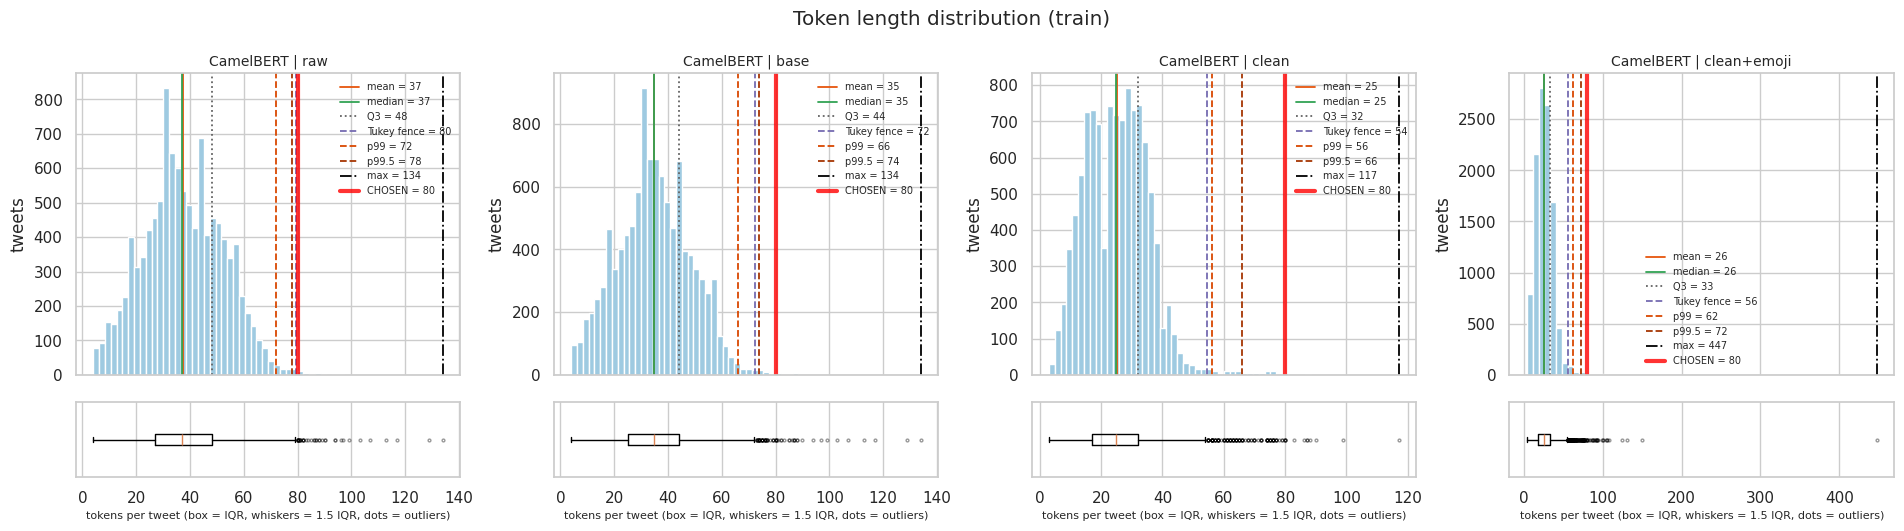

,train (%),val (%),test (%)
cap (base prep),,,
tukey = 72,0.56,0.48,2.90
p99 = 72,0.56,0.48,2.90
p99.5 = 80,0.20,0.00,1.40
mean+3std = 80,0.20,0.00,1.40
max = 136,0.00,0.00,0.03
CHOSEN = 80,0.20,0.00,1.40


In [15]:
cam_tok = sa.tokenizer
CAM_LEN = {pn: np.array([len(x) for x in cam_tok([PREPS[pn](t) for t in train["tweet"]], truncation=True, max_length=512)["input_ids"]]) for pn in PREPS}
cam_stats = {pn: length_stats(L) for pn, L in CAM_LEN.items()}
display(pd.DataFrame(cam_stats).T.round(1))
CAMEL_MAX = max(choose_max_length(s, LENGTH_RULE) for s in cam_stats.values())
print(f"rule = {LENGTH_RULE} -> CAMEL_MAX = {CAMEL_MAX}")
plot_lengths({f"CamelBERT | {pn}": L for pn, L in CAM_LEN.items()}, chosen={f"CamelBERT | {pn}": CAMEL_MAX for pn in CAM_LEN},
             path=FIG / "b2_token_length_distribution.png")
cand = {r: choose_max_length(cam_stats["base"], r) for r in ["tukey", "p99", "p99.5", "mean+3std", "max"]}; cand["CHOSEN"] = CAMEL_MAX
cam_split = {"train": CAM_LEN["base"], **{s: np.array([len(x) for x in cam_tok([PREPS["base"](t) for t in df["tweet"]], truncation=True, max_length=512)["input_ids"]]) for s, df in [("val", val), ("test", test)]}}
display((truncation_table(cam_split, cand) * 100).round(2).rename_axis("cap (base prep)").rename(columns=lambda c: c + " (%)"))

### 3.1 Preprocessing ablation for B2 (val)

In [16]:
def rule_scores(P, y):
    """The TP rule and a few variants. P columns: NEG, NEU, POS."""
    neg = (P.argmax(1) == 0).astype(float)
    out = {"rule: argmax = NEG": (neg, 0.5), "rule: argmax != POS": ((P.argmax(1) != 2).astype(float), 0.5)}
    for name, s in {"score P(NEG) + val threshold": P[:, 0], "score 1-P(POS) + val threshold": 1 - P[:, 2]}.items():
        out[name] = (s, best_threshold(y, s) if y is not None else None)
    return out

rows = []
for prep in PREPS:
    P = get_probs(prep, "val", val)
    sc = rule_scores(P, y_val)
    rows.append({"preprocessing": prep,
                 "rule F1": metrics(y_val, *[sc["rule: argmax = NEG"][0]], 0.5)["f1"],
                 "P(NEG)+thr F1": metrics(y_val, sc["score P(NEG) + val threshold"][0], sc["score P(NEG) + val threshold"][1])["f1"],
                 "P(NEG) PR-AUC": average_precision_score(y_val, P[:, 0]),
                 "sentiment macro-F1 vs gold": f1_score(val["sentiment_id"], P.argmax(1), average="macro")})
b2_prep = pd.DataFrame(rows).set_index("preprocessing")
display(b2_prep.round(4))
B2_PREP = b2_prep["rule F1"].idxmax()
print("Preprocessing retained for B2:", B2_PREP)

,rule F1,P(NEG)+thr F1,P(NEG) PR-AUC,sentiment macro-F1 vs gold
preprocessing,,,,
raw,0.4656,0.4839,0.4725,0.6749
base,0.4590,0.4807,0.4707,0.6668
clean,0.4568,0.4779,0.4705,0.6650
clean+emoji,0.4593,0.4802,0.4720,0.6517


Preprocessing retained for B2: raw


### 3.2 The rule on val: precision / recall / F1 (Q5)

In [17]:
P_val = get_probs(B2_PREP, "val", val)
rows = []
for name, (s, thr) in rule_scores(P_val, y_val).items():
    m = metrics(y_val, s, thr)
    rows.append({"variant": name, "threshold": thr, "precision": m["precision"], "recall": m["recall"],
                 "f1": m["f1"], "macro_f1": m["macro_f1"]})
oracle = (val["sentiment_id"].values == 0).astype(float)           # gold sentiment: upper bound of the idea
m = metrics(y_val, oracle, 0.5)
rows.append({"variant": "ORACLE: gold sentiment = NEG", "threshold": 0.5, "precision": m["precision"],
             "recall": m["recall"], "f1": m["f1"], "macro_f1": m["macro_f1"]})
b2_table = pd.DataFrame(rows).set_index("variant")
display(b2_table.round(4))
print(f"base rate of sarcasm on val = {y_val.mean():.3f}  → precision of the rule should be read against this number")

,threshold,precision,recall,f1,macro_f1
variant,,,,,
rule: argmax = NEG,0.5000,0.3320,0.7788,0.4656,0.6240
rule: argmax != POS,0.5000,0.2086,0.9401,0.3414,0.3715
score P(NEG) + val threshold,0.9390,0.4301,0.5530,0.4839,0.6784
score 1-P(POS) + val threshold,0.9972,0.4039,0.4747,0.4364,0.6530
ORACLE: gold sentiment = NEG,0.5000,0.4194,0.8986,0.5718,0.7061


base rate of sarcasm on val = 0.173  → precision of the rule should be read against this number


### 3.3 What does the rule say about sarcasm ↔ sentiment in the corpus? (gold labels, Q5)

In [18]:
for name, df in [("train", train), ("val", val), ("test", test)]:
    print(f"--- {name}")
    ct = pd.crosstab(df["sentiment"], df["sarcasm"])
    out = pd.DataFrame({"n": ct.sum(1), "P(sarcasm | sentiment)": ct[1] / ct.sum(1),
                        "P(sentiment | sarcastic)": ct[1] / ct[1].sum(),
                        "P(sentiment | not sarcastic)": ct[0] / ct[0].sum()})
    display(out.round(3))

--- train


,n,P(sarcasm | sentiment),P(sentiment | sarcastic),P(sentiment | not sarcastic)
sentiment,,,,
NEG,4025,0.419,0.905,0.261
NEU,4910,0.027,0.071,0.532
POS,1907,0.024,0.025,0.207


--- val


,n,P(sarcasm | sentiment),P(sentiment | sarcastic),P(sentiment | not sarcastic)
sentiment,,,,
NEG,465,0.419,0.899,0.260
NEU,584,0.029,0.078,0.546
POS,206,0.024,0.023,0.194


--- test


,n,P(sarcasm | sentiment),P(sentiment | sarcastic),P(sentiment | not sarcastic)
sentiment,,,,
NEG,1677,0.423,0.864,0.444
NEU,748,0.142,0.129,0.295
POS,575,0.010,0.007,0.261


### 3.4 How good is the sentiment model on this corpus? (gold sentiment of ArSarcasm-v2)

sentiment accuracy: 0.6869 | macro-F1: 0.6749


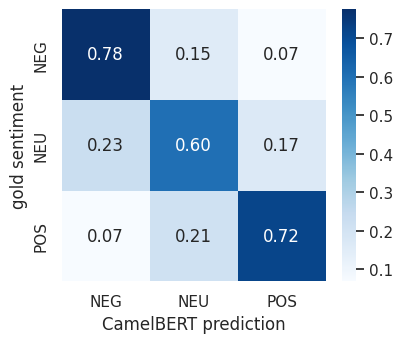

Among tweets predicted NEG: share sarcastic = 0.332 | among predicted NEU/POS: 0.064


In [19]:
pred_s = P_val.argmax(1)
print("sentiment accuracy:", round(accuracy_score(val["sentiment_id"], pred_s), 4),
      "| macro-F1:", round(f1_score(val["sentiment_id"], pred_s, average="macro"), 4))
cm = confusion_matrix(val["sentiment_id"], pred_s, labels=[0, 1, 2], normalize="true")
fig, ax = plt.subplots(figsize=(4.2, 3.6))
sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues", xticklabels=["NEG", "NEU", "POS"], yticklabels=["NEG", "NEU", "POS"], ax=ax)
ax.set_xlabel("CamelBERT prediction"); ax.set_ylabel("gold sentiment"); plt.tight_layout()
plt.savefig(FIG / "b2_sentiment_confusion.png", dpi=200); plt.show()
print("Among tweets predicted NEG: share sarcastic =", round(y_val[pred_s == 0].mean(), 3),
      "| among predicted NEU/POS:", round(y_val[pred_s != 0].mean(), 3))

### 3.5 Contamination diagnostics (Q5)
ArSarcasm-v1 re-annotated **ASTD** (Egyptian) and **SemEval-2017**; the sentiment model was fine-tuned on both. A leak cannot be
*proven* without the provenance of each tweet, but we can look for symptoms: unusually high sentiment accuracy / confidence on the
dialect where the overlap is expected (Egyptian), compared to the others.

In [20]:
def contamination_table(df, P):
    pred = P.argmax(1)
    rows = []
    for dia, g in list(df.groupby("dialect")) + [("ALL", df)]:
        i = g.index.values
        rows.append({"dialect": dia, "n": len(g), "sarcasm_rate": g["sarcasm"].mean(),
                     "sentiment_acc": accuracy_score(g["sentiment_id"], pred[i]),
                     "sentiment_macro_f1": f1_score(g["sentiment_id"], pred[i], average="macro"),
                     "mean_confidence": P[i].max(1).mean(), "share_conf>0.99": (P[i].max(1) > .99).mean(),
                     "rule_F1": f1_score(g["sarcasm"], (pred[i] == 0).astype(int), zero_division=0)})
    return pd.DataFrame(rows).set_index("dialect")
display(contamination_table(val, P_val).round(3))

,n,sarcasm_rate,sentiment_acc,sentiment_macro_f1,mean_confidence,share_conf>0.99,rule_F1
dialect,,,,,,,
egypt,260,0.362,0.719,0.698,0.848,0.169,0.667
gulf,68,0.206,0.706,0.703,0.852,0.147,0.455
levant,55,0.291,0.636,0.594,0.878,0.236,0.609
magreb,5,0.000,0.200,0.133,0.909,0.200,0.000
msa,867,0.107,0.682,0.666,0.854,0.118,0.344
ALL,1255,0.173,0.687,0.675,0.854,0.135,0.466


**Éléments de réponse (Q5) :** (i) la règle « négatif ⇒ sarcastique » a un **rappel** limité (beaucoup de tweets sarcastiques sont positifs/neutres en surface ou négatifs *sans* être jugés sarcastiques) et une **précision** à comparer au taux de base ; l'oracle (sentiment *gold* = NEG) donne la borne haute de l'idée (§3.2) ; (ii) la table §3.3 montre le lien statistique sarcasme ↔ sentiment dans le corpus : si P(sarcasme | NEG) ≫ P(sarcasme | POS) le sentiment est un indice utile mais très insuffisant, et l'écart entre sentiment *de surface* et sentiment *réel* est justement ce qui fait le sarcasme ; (iii) **contamination** : le score n'est **pas garanti exempt** — le modèle a vu ASTD / ArSAS / SemEval pendant son fine-tuning, et ArSarcasm v1 (donc une partie des tweets de train/val/test) vient de ASTD et SemEval-2017. Un score élevé sur les tweets égyptiens, une confiance anormalement haute (§3.5) ou une accuracy de sentiment très supérieure aux scores publiés sont des symptômes ; ce score doit être présenté comme une **borne optimiste** et non comme une mesure de généralisation.

### 3.6 Final B2 models: test scores, predictions, CPU latency (the only place test is used for B2)

In [21]:
P_test = get_probs(B2_PREP, "test", test)
sc_val, sc_test = rule_scores(P_val, y_val), rule_scores(P_test, None)   # thresholds come from val only

def final_b2(name, variant, extra_name=""):
    s_v, thr = sc_val[variant]
    s_t, _ = sc_test[variant]
    mv, mt = metrics(y_val, s_v, thr), metrics(y_test, s_t, thr)
    save_predictions(name, 0, test["id"].values, y_test, s_t, thr)
    return s_v, s_t, thr, mv, mt

N_PARAMS_CAMEL = total_params(sa.model)
sa_cpu = pipeline("text-classification", model=CAMEL, tokenizer=CAMEL, top_k=None, device=-1)
def predict_b2_cpu(texts):
    for t in texts:
        sa_cpu(PREPS[B2_PREP](t), truncation=True, max_length=CAMEL_MAX)
B2_LAT = latency_per_tweet(predict_b2_cpu, val["tweet"].tolist()[:50])
print(f"CPU latency ≈ {B2_LAT*1000:.0f} ms / tweet")

summary = []
for name, variant in [("b2_camelbert_neg_rule", "rule: argmax = NEG"),
                      ("b2_camelbert_pneg_thr", "score P(NEG) + val threshold")]:
    s_v, s_t, thr, mv, mt = final_b2(name, variant)
    log_result(model=name, preprocessing=B2_PREP, seed=0, threshold=thr, train_time=0.0, trained_params=0,
               total_params=N_PARAMS_CAMEL, latency_cpu_s=B2_LAT,
               **{f"val_{k}": v for k, v in mv.items()}, **{f"test_{k}": v for k, v in mt.items()})
    summary.append({"model": name, **{f"val_{k}": mv[k] for k in ("precision", "recall", "f1")},
                    **{f"test_{k}": mt[k] for k in ("precision", "recall", "f1")}})
display(pd.DataFrame(summary).set_index("model").round(4))
print("Test-set contamination symptoms (descriptive only):")
display(contamination_table(test, P_test).round(3))

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

CPU latency ≈ 155 ms / tweet


,val_precision,val_recall,val_f1,test_precision,test_recall,test_f1
model,,,,,,
b2_camelbert_neg_rule,0.3320,0.7788,0.4656,0.4055,0.7734,0.5320
b2_camelbert_pneg_thr,0.4301,0.5530,0.4839,0.4938,0.5371,0.5146


Test-set contamination symptoms (descriptive only):


,n,sarcasm_rate,sentiment_acc,sentiment_macro_f1,mean_confidence,share_conf>0.99,rule_F1
dialect,,,,,,,
egypt,306,0.507,0.627,0.467,0.866,0.255,0.675
gulf,322,0.177,0.621,0.603,0.810,0.149,0.354
levant,47,0.298,0.596,0.448,0.894,0.298,0.421
magreb,2,0.000,0.500,0.333,0.702,0.000,0.000
msa,2323,0.256,0.666,0.630,0.836,0.164,0.527
ALL,3000,0.274,0.656,0.615,0.837,0.173,0.532


## 4. Summary of B (feeds Part G and the report)

In [22]:
res = pd.read_csv(ROOT / "results" / "results.csv")
cols = [c for c in ["model", "preprocessing", "threshold", "val_f1", "val_pr_auc", "val_precision", "val_recall",
                    "test_f1", "test_pr_auc", "total_params", "trained_params", "latency_cpu_s"] if c in res.columns]
display(res[res.model.str.startswith(("b1_", "b2_"))][cols].round(4).reset_index(drop=True))
print("Trivial references on val: never-sarcastic F1 = 0 ; always-sarcastic F1 =", round(2*p/(1+p), 3), "; random PR-AUC =", round(p, 3))

,model,preprocessing,threshold,val_f1,val_pr_auc,val_precision,val_recall,test_f1,test_pr_auc,total_params,trained_params,latency_cpu_s
0,b1_zeroshot_en_author,clean,0.8754,0.4637,0.3995,0.4041,0.5438,NaN,NaN,278811651.0,0,NaN
1,b1_zeroshot_fr,clean,0.5037,0.4132,0.3413,0.3060,0.6359,NaN,NaN,278811651.0,0,NaN
2,b1_zeroshot_ar,clean,0.5015,0.4111,0.3491,0.2780,0.7880,NaN,NaN,278811651.0,0,NaN
3,b1_zeroshot_en,clean,0.5276,0.4090,0.3404,0.3036,0.6267,NaN,NaN,278811651.0,0,NaN
4,b1_zeroshot_ensemble3,clean,0.7323,0.4056,0.3449,0.2804,0.7327,NaN,NaN,278811651.0,0,NaN
5,b1_zeroshot_ar_author,clean,0.7894,0.3892,0.3220,0.2753,0.6636,NaN,NaN,278811651.0,0,NaN
6,b1_zeroshot_en_author,raw,0.8739,0.4741,0.4379,0.3963,0.5899,0.4876,0.4308,278811651.0,0,0.7458
7,b2_camelbert_neg_rule,raw,0.5000,0.4656,0.2968,0.3320,0.7788,0.5320,0.3756,109083651.0,0,0.1555
8,b2_camelbert_pneg_thr,raw,0.9390,0.4839,0.4725,0.4301,0.5530,0.5146,0.4948,109083651.0,0,0.1555


Trivial references on val: never-sarcastic F1 = 0 ; always-sarcastic F1 = 0.295 ; random PR-AUC = 0.173


**À reporter dans le compte-rendu :** Q4 → §2.1–2.2 (F1/PR-AUC par formulation ar/fr/en, Δ, corrélations) + texte §2.7 ; Q5 → §3.2 (P/R/F1, oracle), §3.3 (relation sarcasme–sentiment), §3.5 (contamination) ; Q3 (partie PLM) → ablations §2.5 et §3.1.